In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.data.labels import load_labels

from src.analysis.bounding_box_analysis import (
    create_bounding_box_dataframe,
    bounding_boxes_per_patient
)

NEW LABELS.PY LOADED


In [2]:
csv_path = Path(
    "../data/raw/rsna-pneumonia-detection-challenge/stage_2_train_labels.csv"
)

print("CSV exists:", csv_path.exists())

CSV exists: True


In [3]:
labels, stats = load_labels(csv_path)

print("Total patients:", stats["num_patients"])
print("Positive cases:", stats["positive_cases"])
print("Negative cases:", stats["negative_cases"])
print("Total bounding boxes:", stats["total_boxes"])

Total patients: 26684
Positive cases: 6012
Negative cases: 20672
Total bounding boxes: 9555


In [4]:
bbox_df = create_bounding_box_dataframe(labels)

print("Total bounding boxes:", len(bbox_df))

bbox_df.head()

Total bounding boxes: 9555


,patient_ids,x,y,width,height,area,aspect_ratio,center_x,center_y
0,00436515-870c-4b36-a041-de91049b9ab4,264.0,152.0,213.0,379.0,80727.0,0.562005,370.5,341.5
1,00436515-870c-4b36-a041-de91049b9ab4,562.0,152.0,256.0,453.0,115968.0,0.565121,690.0,378.5
2,00704310-78a8-4b38-8475-49f4573b2dbb,323.0,577.0,160.0,104.0,16640.0,1.538462,403.0,629.0
3,00704310-78a8-4b38-8475-49f4573b2dbb,695.0,575.0,162.0,137.0,22194.0,1.182482,776.0,643.5
4,00aecb01-a116-45a2-956c-08d2fa55433f,288.0,322.0,94.0,135.0,12690.0,0.696296,335.0,389.5


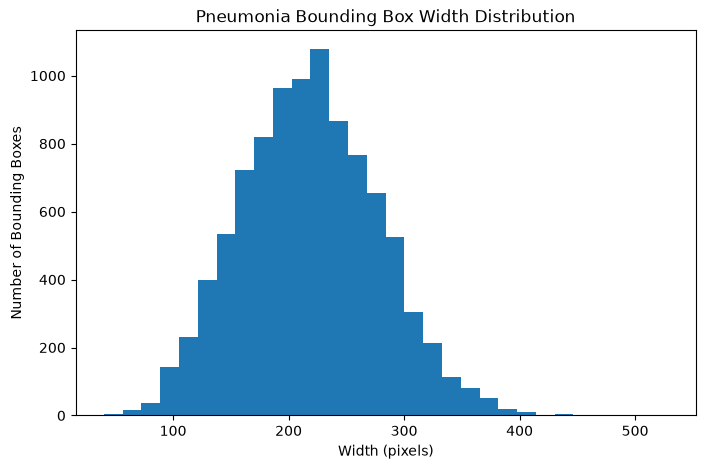

In [5]:
# Bounding Box Width

plt.figure(figsize=(8, 5))

plt.hist(
    bbox_df["width"],
    bins=30
)

plt.title("Pneumonia Bounding Box Width Distribution")
plt.xlabel("Width (pixels)")
plt.ylabel("Number of Bounding Boxes")

plt.show()

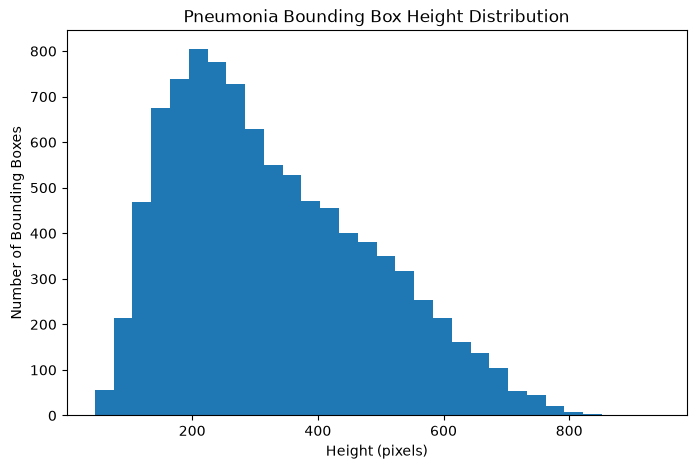

In [6]:
# Bounding Box Height

plt.figure(figsize=(8, 5))

plt.hist(
    bbox_df["height"],
    bins=30
)

plt.title("Pneumonia Bounding Box Height Distribution")
plt.xlabel("Height (pixels)")
plt.ylabel("Number of Bounding Boxes")

plt.show()

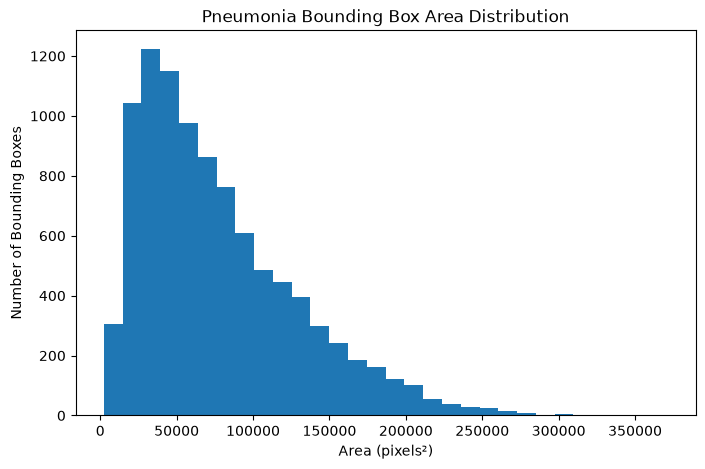

In [7]:
# Bounding Box Area

plt.figure(figsize=(8, 5))

plt.hist(
    bbox_df["area"],
    bins=30
)

plt.title("Pneumonia Bounding Box Area Distribution")
plt.xlabel("Area (pixels²)")
plt.ylabel("Number of Bounding Boxes")

plt.show()

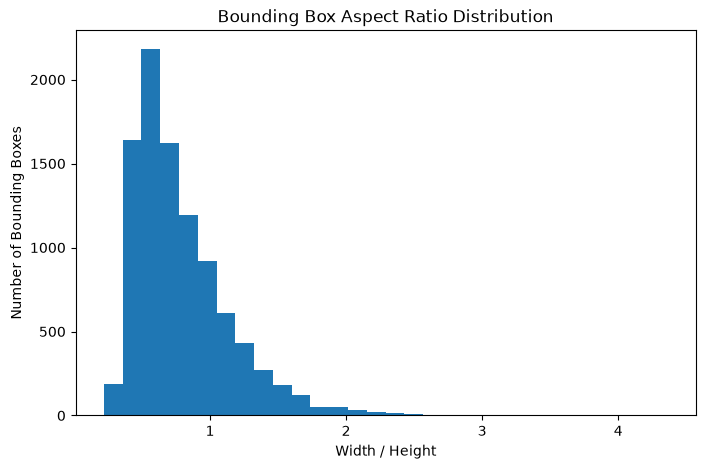

In [8]:
# Bounding Box Aspect Ratio

plt.figure(figsize=(8, 5))

plt.hist(
    bbox_df["aspect_ratio"].dropna(),
    bins=30
)

plt.title("Bounding Box Aspect Ratio Distribution")
plt.xlabel("Width / Height")
plt.ylabel("Number of Bounding Boxes")

plt.show()

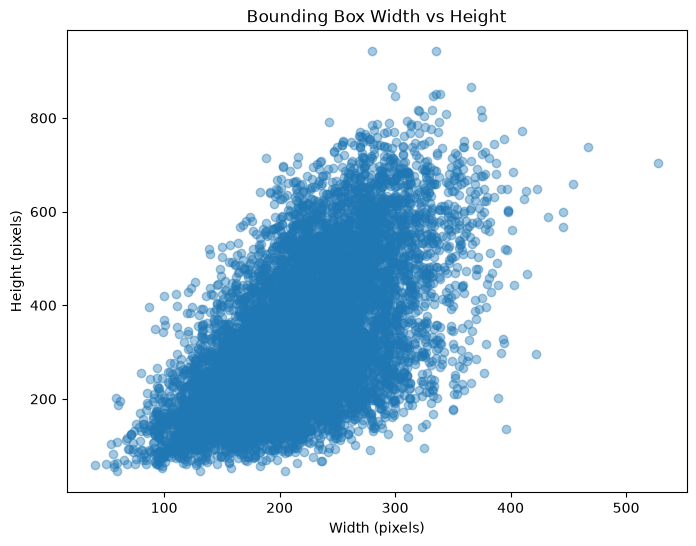

In [9]:
# Width vs Height

plt.figure(figsize=(8, 6))

plt.scatter(
    bbox_df["width"],
    bbox_df["height"],
    alpha=0.4
)

plt.title("Bounding Box Width vs Height")
plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")

plt.show()

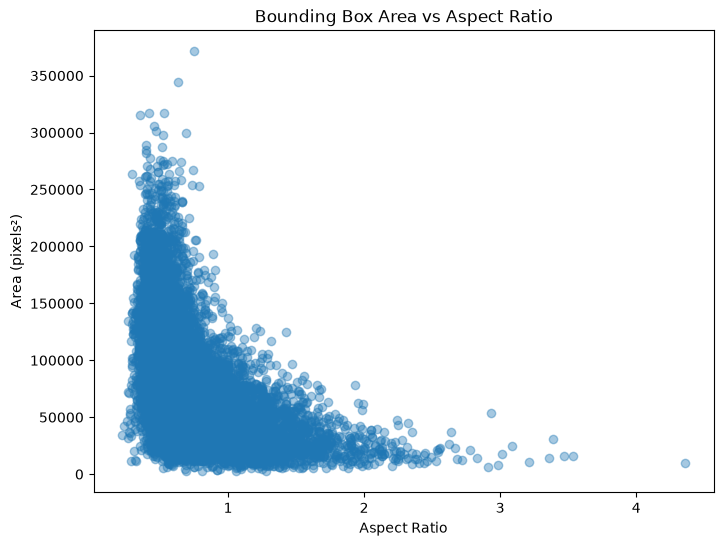

In [10]:
# Area vs Aspect Ratio

plt.figure(figsize=(8, 6))

plt.scatter(
    bbox_df["aspect_ratio"],
    bbox_df["area"],
    alpha=0.4
)

plt.title("Bounding Box Area vs Aspect Ratio")
plt.xlabel("Aspect Ratio")
plt.ylabel("Area (pixels²)")

plt.show()

In [11]:
# Number of Boxes per Patient
patient_bbox_df = bounding_boxes_per_patient(labels)

patient_bbox_df.head()

patient_bbox_df["num_boxes"].value_counts().sort_index()


num_boxes
0    20672
1     2614
2     3266
3      119
4       13
Name: count, dtype: int64

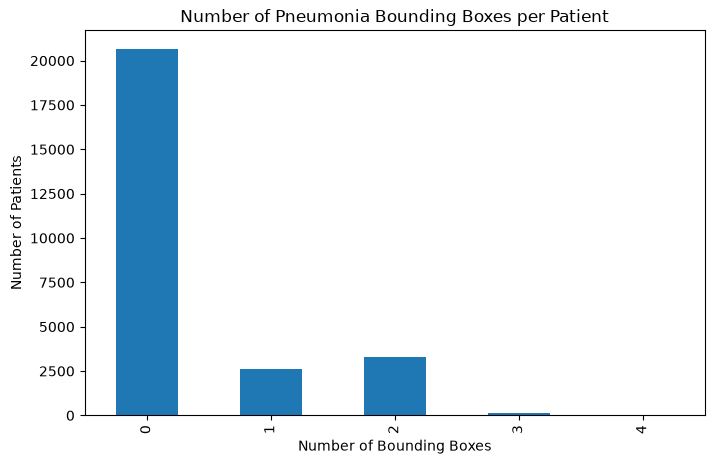

In [12]:
# Box Frequency

patient_bbox_df["num_boxes"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Number of Pneumonia Bounding Boxes per Patient")
plt.xlabel("Number of Bounding Boxes")
plt.ylabel("Number of Patients")

plt.show()

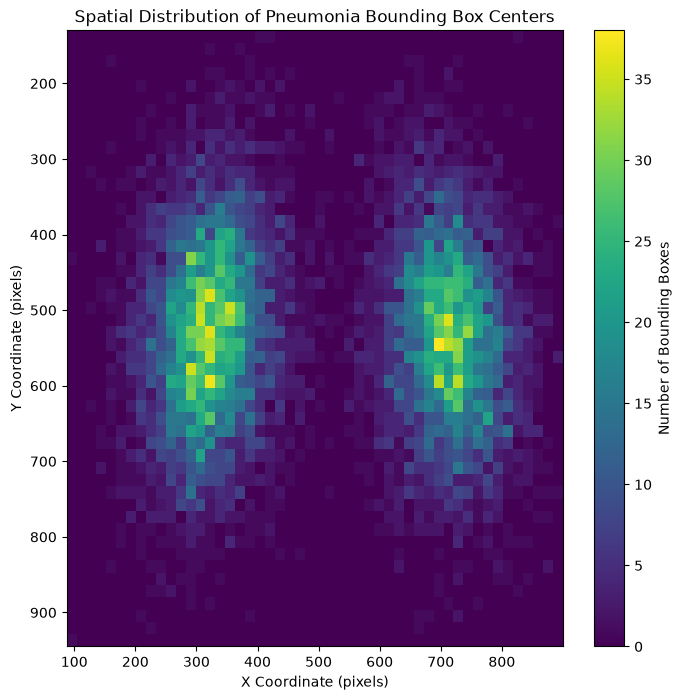

In [13]:
# Bounding Box Center Heatmap

plt.figure(figsize=(8, 8))

plt.hist2d(
    bbox_df["center_x"],
    bbox_df["center_y"],
    bins=50
)

plt.colorbar(
    label="Number of Bounding Boxes"
)

plt.title("Spatial Distribution of Pneumonia Bounding Box Centers")

plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")

plt.gca().invert_yaxis()

plt.show()

In [15]:
# Overlay Bounding Boxes on X-rays

import matplotlib.patches as patches
from src.data.dicom_loader import load_dicom

sample_patient = bbox_df.iloc[0]["patient_ids"]

image_path = (
    Path(
        "../data/raw/rsna-pneumonia-detection-challenge/"
        "stage_2_train_images"
    )
    / f"{sample_patient}.dcm"
)

image, _ = load_dicom(image_path)

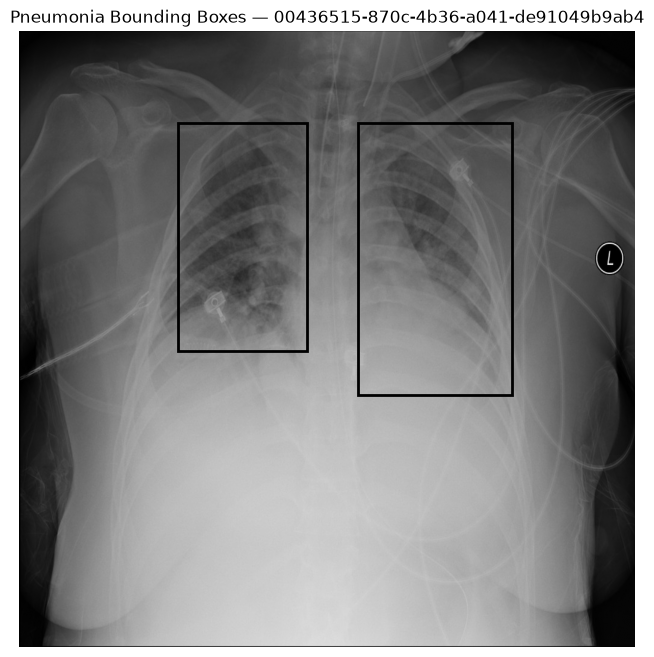

In [17]:
fig, ax = plt.subplots(figsize=(8, 8))

ax.imshow(
    image,
    cmap="gray"
)

patient_boxes = bbox_df[
    bbox_df["patient_ids"] == sample_patient
]

for _, box in patient_boxes.iterrows():

    rect = patches.Rectangle(
        (
            box["x"],
            box["y"]
        ),
        box["width"],
        box["height"],
        fill=False,
        linewidth=2
    )

    ax.add_patch(rect)

ax.set_title(
    f"Pneumonia Bounding Boxes — {sample_patient}"
)

ax.axis("off")

plt.show()

In [18]:
# Summary Statistics

bbox_df[
    [
        "width",
        "height",
        "area",
        "aspect_ratio"
    ]
].describe()

,width,height,area,aspect_ratio
count,9555.000000,9555.000000,9555.000000,9555.000000
mean,218.471376,329.269702,77523.448038,0.786864
std,59.289475,157.750755,51807.689206,0.359128
min,40.000000,45.000000,2320.000000,0.219144
25%,177.000000,203.000000,37535.500000,0.529671
50%,217.000000,298.000000,64829.000000,0.690789
75%,259.000000,438.000000,106491.500000,0.955882
max,528.000000,942.000000,371184.000000,4.361702


In [19]:
patient_bbox_df[
    "num_boxes"
].describe()

count    26684.000000
mean         0.358080
std          0.712231
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          4.000000
Name: num_boxes, dtype: float64

In [20]:
# Find Extreme Bounding Boxes

bbox_df.nsmallest(
    10,
    "area"
)

,patient_ids,x,y,width,height,area,aspect_ratio,center_x,center_y
2770,5620c301-4fee-478e-bdb0-124a00010443,231.0,263.0,40.0,58.0,2320.0,0.689655,251.0,292.0
3276,6c490407-f039-4eaf-94c8-1bff41b09f6c,188.0,516.0,59.0,46.0,2714.0,1.282609,217.5,539.0
2779,567f81ac-7be3-4663-9a3b-826319bcd6ba,791.0,692.0,57.0,54.0,3078.0,1.055556,819.5,719.0
8302,e77e8d88-11e5-4d15-8dfb-abcd5c09c9f0,711.0,564.0,50.0,62.0,3100.0,0.806452,736.0,595.0
8319,e7f64666-2118-4f2f-a1e9-86d9f1eb7573,800.0,384.0,57.0,62.0,3534.0,0.919355,828.5,415.0
8255,e542d5db-28c5-4e73-aa47-a441143887cc,531.0,524.0,59.0,64.0,3776.0,0.921875,560.5,556.0
965,2dce719f-1702-406f-a471-03f033f1822a,214.0,340.0,68.0,62.0,4216.0,1.096774,248.0,371.0
9250,1d247b6c-0687-40bf-839e-fd30e01c585d,776.0,337.0,65.0,69.0,4485.0,0.942029,808.5,371.5
3736,78abc3f5-ac62-4e42-a6b4-1c44e09cb566,749.0,539.0,75.0,60.0,4500.0,1.250000,786.5,569.0
9007,03a512bc-1162-404e-8c71-dc9e0dc7258f,815.0,604.0,56.0,82.0,4592.0,0.682927,843.0,645.0


In [21]:
bbox_df.nlargest(
    10,
    "area"
)

,patient_ids,x,y,width,height,area,aspect_ratio,center_x,center_y
307,097788d4-cb88-4457-8e71-0ca7a3da2216,226.0,189.0,528.0,703.0,371184.0,0.751067,490.0,540.5
444,0c391e0f-9927-48ce-801f-02eb000f72c3,486.0,230.0,467.0,738.0,344646.0,0.632791,719.5,599.0
2129,3e62e51c-befb-4a66-b28e-fc469b19e4a8,148.0,87.0,366.0,867.0,317322.0,0.422145,331.0,520.5
4976,9dc1e167-1784-45cd-9fad-9bd7c8c7d904,534.0,101.0,410.0,773.0,316930.0,0.530401,739.0,487.5
2130,3e62e51c-befb-4a66-b28e-fc469b19e4a8,620.0,82.0,335.0,942.0,315570.0,0.355626,787.5,553.0
4662,92a2dfab-f33a-4324-953a-afe96680c541,520.0,201.0,374.0,817.0,305558.0,0.457772,707.0,609.5
5479,aa47c55a-7cf7-4105-9132-de080664f052,525.0,103.0,375.0,803.0,301125.0,0.466999,712.5,504.5
729,17f68ac3-2385-4b13-b8c0-66ba8b343205,398.0,101.0,454.0,659.0,299186.0,0.688923,625.0,430.5
265,08da8f40-b186-473b-9fa3-1caa4ecdc02b,496.0,130.0,394.0,755.0,297470.0,0.521854,693.0,507.5
1817,3accdbb1-0300-4065-8757-94eb3dd213c3,621.0,172.0,339.0,852.0,288828.0,0.397887,790.5,598.0
